# 模块 2：航迹关联与卡尔曼滤波示例

本 notebook 直接复用 `tracker.py` 中的纯算法，展示恒速目标的稳定 ID、`age`、预测/更新和空量测预测。不导入 ROS，不复制算法实现。

In [2]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
while root != root.parent and not (root / 'code' / 'tracker.py').is_file():
    root = root.parent
assert (root / 'code' / 'tracker.py').is_file(), '未找到项目根目录'
sys.path.insert(0, str(root / 'code'))

import numpy as np
from tracker import KalmanTracker, track_state_to_track

print('tracker module:', root / 'code' / 'tracker.py')

tracker module: /home/demo/桌面/ai4/code/tracker.py


## 1. 恒速量测：ID 稳定且速度收敛

以 10 Hz 提供一条三维恒速轨迹，每帧位移远小于 2 m 关联门限。

In [3]:
tracker = KalmanTracker(process_noise=0.05, measurement_noise=0.05)
dt = 0.1
velocity = np.array([0.4, -0.2, 0.1])
rows = []
for frame in range(20):
    measurement = np.array([1.0, 2.0, 3.0]) + velocity * frame * dt
    state = tracker.step([measurement], dt=dt, timestamp=frame * dt)[0]
    if frame in (0, 1, 5, 10, 19):
        rows.append((frame, state.id, state.age, state.state[:3].copy(), state.state[3:].copy()))

print('%5s %3s %4s %-28s %s' % ('frame', 'id', 'age', 'position', 'velocity'))
for frame, track_id, age, position, estimate in rows:
    print('%5d %3d %4d %-28s %s' % (frame, track_id, age, np.round(position, 4), np.round(estimate, 4)))
assert {row[1] for row in rows} == {0}
assert rows[-1][2] == 20

frame  id  age position                     velocity
    0   0    1 [1. 2. 3.]                   [0. 0. 0.]
    1   0    2 [1.0381 1.9809 3.0095]       [ 0.0038 -0.0019  0.0009]
    5   0    6 [1.1737 1.9131 3.0434]       [ 0.2707 -0.1354  0.0677]
   10   0   11 [1.3899 1.8051 3.0975]       [ 0.3778 -0.1889  0.0945]
   19   0   20 [1.7571 1.6215 3.1893]       [ 0.397  -0.1985  0.0993]


## 2. 预测与更新

先单独预测一个时间步，再用新量测更新，观察位置修正。

In [4]:
before = tracker.active_tracks[0].state.copy()
tracker.predict(0.2)
predicted = tracker.active_tracks[0].state.copy()
measurement = predicted[:3] + np.array([0.10, -0.05, 0.02])
association = tracker.associate([measurement])
tracker.update(measurement)
updated = tracker.active_tracks[0].state.copy()
print('before   :', np.round(before, 4))
print('predicted:', np.round(predicted, 4))
print('associate:', association)
print('updated  :', np.round(updated, 4))
assert association == {0: 0}

before   : [ 1.7571  1.6215  3.1893  0.397  -0.1985  0.0993]
predicted: [ 1.8365  1.5818  3.2091  0.397  -0.1985  0.0993]
associate: {0: 0}
updated  : [ 1.8581  1.5709  3.2135  0.4145 -0.2072  0.1027]


## 3. 短段空量测与恢复

空量测仍执行预测并增加 `age`；3 帧少于默认删除条件，恢复时应关联回原 ID。

In [5]:
track_id = tracker.active_tracks[0].id
empty_rows = []
for missed in range(1, 4):
    state = tracker.step([], dt=dt, timestamp=None)[0]
    empty_rows.append((missed, state.id, state.age, state.state[:3].copy()))
for row in empty_rows:
    print('empty=%d id=%d age=%d predicted=%s' % (row[0], row[1], row[2], np.round(row[3], 4)))
recovery_measurement = tracker.active_tracks[0].state[:3] + np.array([0.02, 0.0, 0.0])
recovered = tracker.step([recovery_measurement], dt=dt, timestamp=3.0)[0]
published = track_state_to_track(recovered)
print('recovered:', published)
assert recovered.id == track_id

empty=1 id=0 age=22 predicted=[1.8996 1.5502 3.2237]
empty=2 id=0 age=23 predicted=[1.941  1.5295 3.234 ]
empty=3 id=0 age=24 predicted=[1.9825 1.5088 3.2443]
recovered: Track(id=0, position=(2.0178511813279933, 1.4939133393259036, 3.251636608951982), velocity=(0.41021722387162796, -0.20311712991254066, 0.10070313129853617), covariance=(0.014194649949498733, 0.0, 0.0, 0.009957410116365447, 0.0, 0.0, 0.0, 0.014194649949498733, 0.0, 0.0, 0.009957410116365447, 0.0, 0.0, 0.0, 0.014194649949498733, 0.0, 0.0, 0.009957410116365447, 0.009957410116365447, 0.0, 0.0, 0.011172768151995827, 0.0, 0.0, 0.0, 0.009957410116365447, 0.0, 0.0, 0.011172768151995827, 0.0, 0.0, 0.0, 0.009957410116365447, 0.0, 0.0, 0.011172768151995827), age=25)


## 4. 效果图：恒速跟踪精度

用一段带噪声的恒速轨迹（中间 5 帧空量测）把 `tracker.py` 的行为画出来：轨迹贴合度、位置误差、速度收敛与不确定度变化。

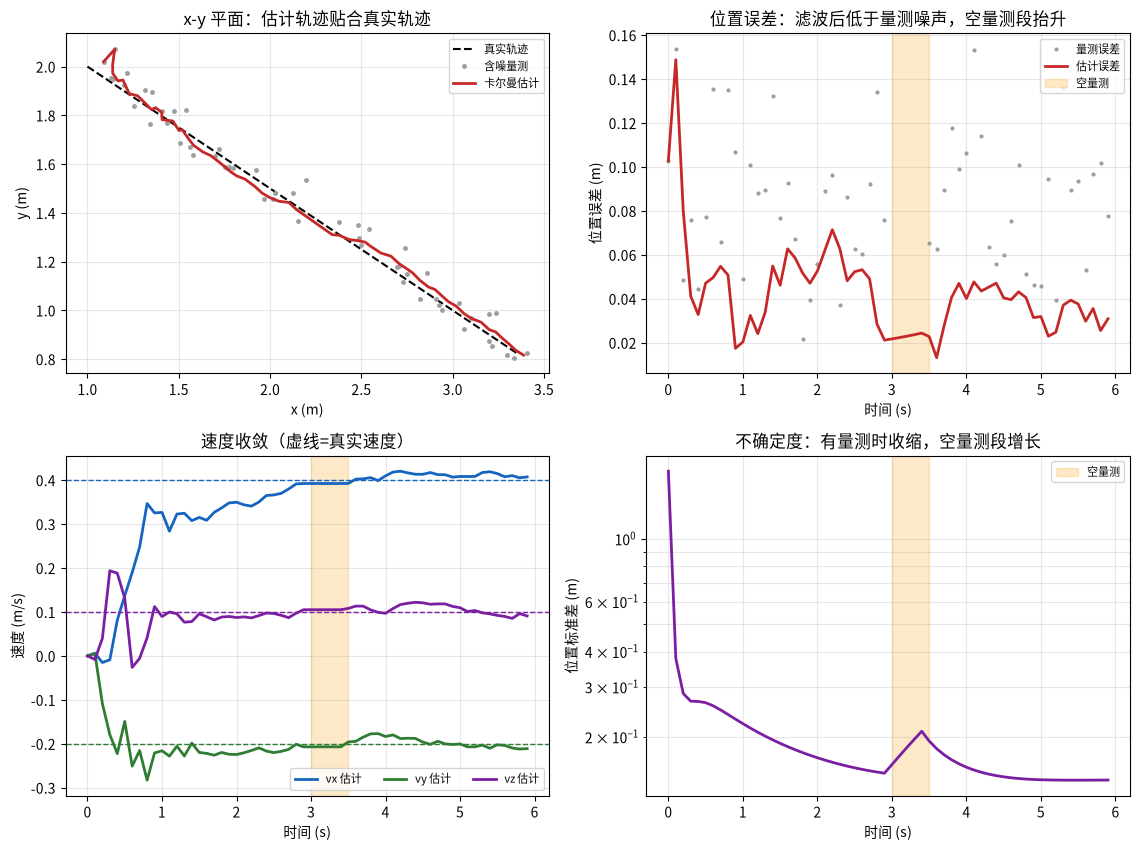

In [4]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
while root != root.parent and not (root / 'code' / 'tracker.py').is_file():
    root = root.parent
assert (root / 'code' / 'tracker.py').is_file(), '未找到项目根目录'
if str(root / 'code') not in sys.path:
    sys.path.insert(0, str(root / 'code'))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from tracker import KalmanTracker

plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

dt = 0.1
frames = np.arange(0, 60)
start = np.array([1.0, 2.0, 3.0])
velocity = np.array([0.4, -0.2, 0.1])
gap = list(range(30, 35))            # 连续 5 帧空量测（<= max_missed_frames，不删除）
rng = np.random.RandomState(0)

tracker = KalmanTracker(process_noise=0.05, measurement_noise=0.05)
truth, measured, states = [], [], []
for frame in frames:
    true_position = start + velocity * frame * dt
    measurement = None if frame in gap else true_position + rng.normal(0.0, 0.05, 3)
    result = tracker.step([] if measurement is None else [measurement], dt=dt, timestamp=frame * dt)
    truth.append(true_position)
    measured.append(np.full(3, np.nan) if measurement is None else measurement)
    states.append((result[0].state.copy(), result[0].cov.copy()))

truth = np.array(truth)
measured = np.array(measured)
estimated = np.array([item[0] for item in states])
position_error = np.linalg.norm(estimated[:, :3] - truth, axis=1)
measurement_error = np.linalg.norm(measured - truth, axis=1)
sigma = np.array([float(np.sqrt(np.trace(item[1][:3, :3]))) for item in states])
gap_start, gap_end = gap[0] * dt, (gap[-1] + 1) * dt

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.6))

ax = axes[0, 0]
ax.plot(truth[:, 0], truth[:, 1], 'k--', lw=1.5, label='真实轨迹')
ax.plot(measured[:, 0], measured[:, 1], '.', color='0.62', ms=5, label='含噪量测')
ax.plot(estimated[:, 0], estimated[:, 1], color='#c62828', lw=2, label='卡尔曼估计')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('x-y 平面：估计轨迹贴合真实轨迹')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[0, 1]
ax.plot(frames * dt, measurement_error, '.', color='0.62', ms=4, label='量测误差')
ax.plot(frames * dt, position_error, color='#c62828', lw=2, label='估计误差')
ax.axvspan(gap_start, gap_end, color='#f9a825', alpha=0.25, label='空量测')
ax.set_xlabel('时间 (s)')
ax.set_ylabel('位置误差 (m)')
ax.set_title('位置误差：滤波后低于量测噪声，空量测段抬升')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1, 0]
for index, name, color in zip(range(3), ['vx', 'vy', 'vz'], ['#1565c0', '#2e7d32', '#7b1fa2']):
    ax.plot(frames * dt, estimated[:, 3 + index], color=color, lw=2, label='%s 估计' % name)
    ax.axhline(velocity[index], color=color, ls='--', lw=1)
ax.axvspan(gap_start, gap_end, color='#f9a825', alpha=0.25)
ax.set_xlabel('时间 (s)')
ax.set_ylabel('速度 (m/s)')
ax.set_title('速度收敛（虚线=真实速度）')
ax.legend(fontsize=8, ncol=3)
ax.grid(alpha=0.3)

ax = axes[1, 1]
ax.plot(frames * dt, sigma, color='#7b1fa2', lw=2)
ax.axvspan(gap_start, gap_end, color='#f9a825', alpha=0.25, label='空量测')
ax.set_yscale('log')
ax.set_xlabel('时间 (s)')
ax.set_ylabel('位置标准差 (m)')
ax.set_title('不确定度：有量测时收缩，空量测段增长')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

## 5. 效果图：多目标关联与航迹生命周期

两个平行运动的目标；其中 B 连续丢失 8 帧（> `max_missed_frames=5`）后被删除，重现时按新目标分配 ID。

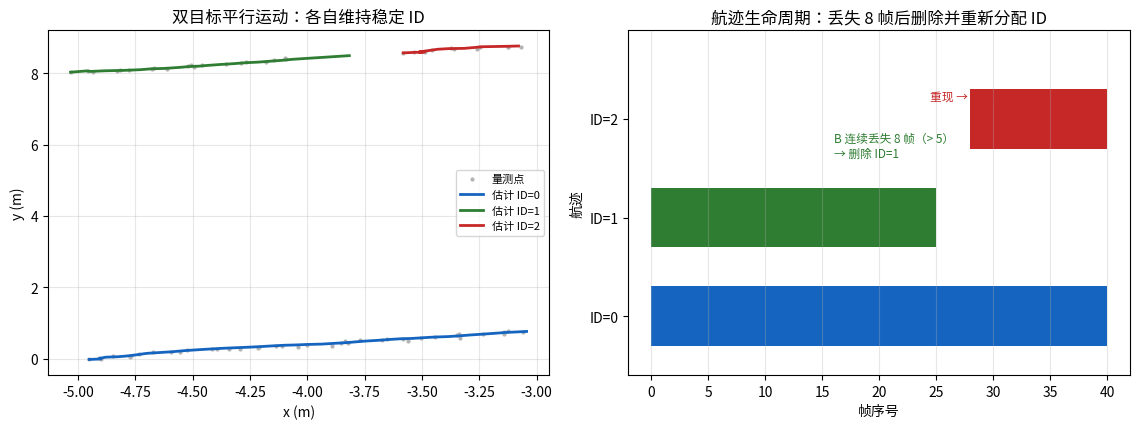

In [7]:
dt = 0.1
frames = np.arange(0, 40)
rng = np.random.RandomState(1)
paths = {'A': (np.array([-5.0, 0.0, 3.0]), np.array([0.5, 0.2, 0.0])),
         'B': (np.array([-5.0, 8.0, 3.0]), np.array([0.5, 0.2, 0.0]))}
missing = range(20, 28)              # B 连续 8 帧丢失（> max_missed_frames=5）

tracker = KalmanTracker(process_noise=0.05, measurement_noise=0.05)
measurement_points = []
trails = {}
alive_frames = {}
for frame in frames:
    measurements = []
    for name in ('A', 'B'):
        if name == 'B' and frame in missing:
            continue
        origin, speed = paths[name]
        measurements.append(origin + speed * frame * dt + rng.normal(0.0, 0.03, 3))
    measurement_points.extend(measurements)
    for state in tracker.step(measurements, dt=dt, timestamp=frame * dt):
        trails.setdefault(state.id, []).append(state.state[:2].copy())
        alive_frames.setdefault(state.id, []).append(frame)

palette = ['#1565c0', '#2e7d32', '#c62828', '#7b1fa2']
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

ax = axes[0]
measurement_points = np.array(measurement_points)
ax.plot(measurement_points[:, 0], measurement_points[:, 1], '.', color='0.7', ms=4, label='量测点')
for track_id in sorted(trails):
    points = np.array(trails[track_id])
    ax.plot(points[:, 0], points[:, 1], color=palette[track_id % len(palette)], lw=2,
            label='估计 ID=%d' % track_id)
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('双目标平行运动：各自维持稳定 ID')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
for track_id in sorted(alive_frames):
    ax.broken_barh([(frame, 1) for frame in alive_frames[track_id]],
                   (track_id - 0.3, 0.6), facecolors=palette[track_id % len(palette)])
ax.set_yticks(sorted(alive_frames))
ax.set_yticklabels(['ID=%d' % track_id for track_id in sorted(alive_frames)])
ax.set_ylim(-0.6, max(alive_frames) + 0.9)
ax.set_xlabel('帧序号')
ax.set_ylabel('航迹')
ax.set_title('航迹生命周期：丢失 8 帧后删除并重新分配 ID')
ax.text(16.0, 1.62, 'B 连续丢失 8 帧（> 5）\n→ 删除 ID=1', fontsize=8.5, color='#2e7d32')
ax.text(24.5, 2.2, '重现 → 新建 ID=2', fontsize=8.5, color='#c62828')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()